# Milestone 3: Neural fitted Q-learning on CarRacing (requirement 2 groundwork)

**Goal:** the first *deep* RL algorithm: replace the Q-table with a neural network that reads raw pixels, in a second environment, `CarRacing`. Gymnasium now ships it as `CarRacing-v3` (the course used `-v0`) with the discrete action set (do nothing, steer right, steer left, gas, brake).

**How this notebook is organised.** Training CarRacing takes ~30 minutes per run on 2 CPU cores, so the training runs are launched with `experiments/run_carracing.py` (same code as the cell below) and this notebook loads the logged results. A short live smoke run is included so the training loop can be seen executing.

In [1]:
import sys, json, glob; sys.path.insert(0, "..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, gymnasium as gym, torch
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
from src import carracing as C
def load(variant):
    return [json.load(open(p)) for p in sorted(glob.glob(f"../results/car_{variant}_s*.json"))]
def smooth(hist, grid, window=15):
    st = np.array([h[0] for h in hist]); rt = np.array([h[1] for h in hist]); out = []
    for g in grid:
        idx = np.where(st <= g)[0][-window:]; out.append(rt[idx].mean() if len(idx) else np.nan)
    return np.array(out)
env = gym.make("CarRacing-v3", continuous=False)
print("observation space:", env.observation_space); print("action space:     ", env.action_space)
print("""Problem components
  state  : 96x96 RGB image of the car and track
  actions: 0 do nothing, 1 steer right, 2 steer left, 3 gas, 4 brake
  reward : -0.1 per frame, +1000/N for each of the N track tiles visited
  end    : all tiles visited, car leaves the playfield (-100), or time limit""")

observation space: Box(0, 255, (96, 96, 3), uint8)
action space:      Discrete(5)
Problem components
  state  : 96x96 RGB image of the car and track
  actions: 0 do nothing, 1 steer right, 2 steer left, 3 gas, 4 brake
  reward : -0.1 per frame, +1000/N for each of the N track tiles visited
  end    : all tiles visited, car leaves the playfield (-100), or time limit


## 1. Extract the state the agent is in

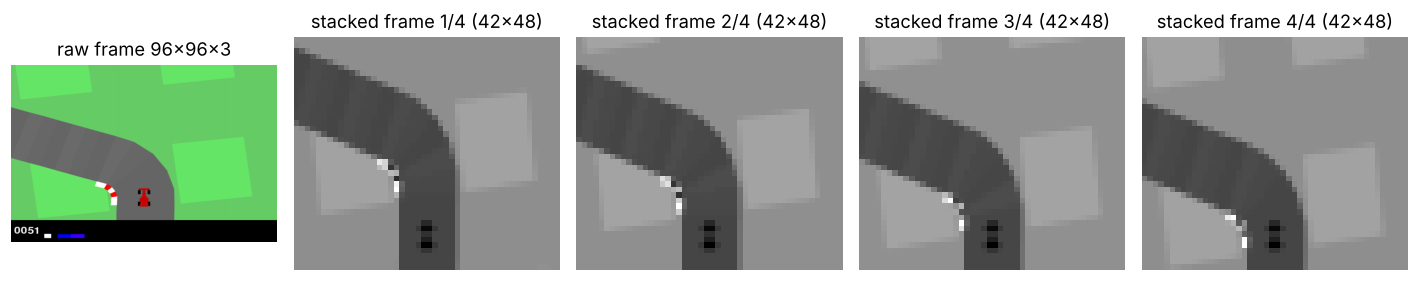

state tensor: (4, 42, 48) uint8 | preprocessing: crop status bar, grayscale, downsample x2, stack last 4 frames, repeat each action 4x


In [2]:
e = C.CarEnv(render=True); s = e.reset(seed=3)
for _ in range(25): s, r, done = e.step(3)                    # drive forward a bit
raw = e.env.render()
fig, ax = plt.subplots(1, 5, figsize=(13, 2.8))
ax[0].imshow(raw); ax[0].set_title("raw frame 96x96x3")
for i in range(4): ax[i+1].imshow(s[i], cmap="gray"); ax[i+1].set_title(f"stacked frame {i+1}/4 (42x48)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("../docs/img/m3_state.png"); plt.show()
print("state tensor:", s.shape, s.dtype, "| preprocessing: crop status bar, grayscale, downsample x2, stack last 4 frames, repeat each action 4x")

## 2. Hyperparameters

In [3]:
import inspect
sig = inspect.signature(C.train)
dqn_only = {"buffer", "target_sync", "update_every", "warmup"}      # used by milestone 4 only (replay + target network)
hp = {k: v.default for k, v in sig.parameters.items() if v.default is not inspect.Parameter.empty and k not in {"log", "variant"} | dqn_only}
hp["batch"] = "1 (online: latest transition only)"
hp["total_steps (used in the logged runs)"] = 50_000
print(json.dumps(hp, indent=1)); print("episode cap:", C.MAX_STEPS, "agent steps | no-progress limit:", C.PATIENCE, "steps")

{
 "total_steps": 50000,
 "seed": 0,
 "gamma": 0.97,
 "lr": 0.0001,
 "batch": "1 (online: latest transition only)",
 "eps_end": 0.05,
 "eps_frac": 0.6,
 "total_steps (used in the logged runs)": 50000
}
episode cap: 250 agent steps | no-progress limit: 50 steps


## 3. Neural network architecture
The brief mentions a multilayer perceptron; because the input is an image I use a small convolutional feature extractor followed by a fully connected head (an MLP on top of the conv features).

In [4]:
q = C.QCNN(); print(q); print("parameters:", sum(p.numel() for p in q.parameters()))

QCNN(
  (conv): Sequential(
    (0): Conv2d(4, 16, kernel_size=(4, 4), stride=(2, 2))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2))
    (3): ReLU()
    (4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (head): Sequential(
    (0): Linear(in_features=2016, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=5, bias=True)
  )
)
parameters: 273749


## 4. Exploration strategy: epsilon-greedy, linear decay

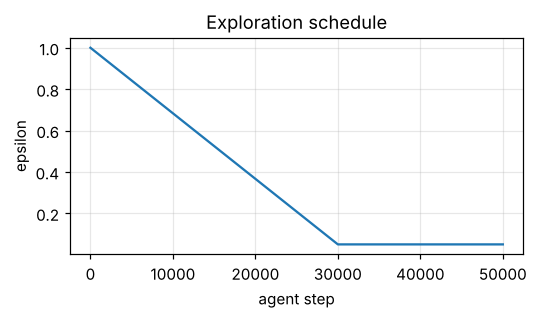

In [5]:
steps = np.arange(0, 50_001, 500); eps = np.maximum(0.05, 1 - 0.95 * steps / (0.6 * 50_000))
plt.figure(figsize=(5, 3)); plt.plot(steps, eps); plt.xlabel("agent step"); plt.ylabel("epsilon"); plt.title("Exploration schedule"); plt.tight_layout()
plt.savefig("../docs/img/m3_epsilon.png"); plt.show()

## 5. Forward pass through the network

In [6]:
with torch.no_grad(): qv = q(torch.as_tensor(s).unsqueeze(0))
print("Q-values for the 5 actions (untrained network):", qv.numpy().round(3)); print("greedy action:", int(qv.argmax()))

Q-values for the 5 actions (untrained network): [[-0.076 -0.045  0.095  0.04   0.029]]
greedy action: 2


## 6. Training loop
Variant `nfq` is the neural fitted Q-learning agent of this milestone: epsilon-greedy, **one gradient step per transition, learning from the latest transition only, bootstrapping from the same network** (no replay, no target network; those are milestone 4).

In [7]:
# Live smoke run (300 agent steps) to show the loop executing. The logged results below come from 50,000-step runs.
q_smoke, h_smoke = C.train("nfq", total_steps=300, seed=0, log=print)
print("smoke run finished:", len(h_smoke), "episodes")

smoke run finished: 3 episodes


## 7. Visualize the progress (logged 50,000-step runs, 2 seeds)

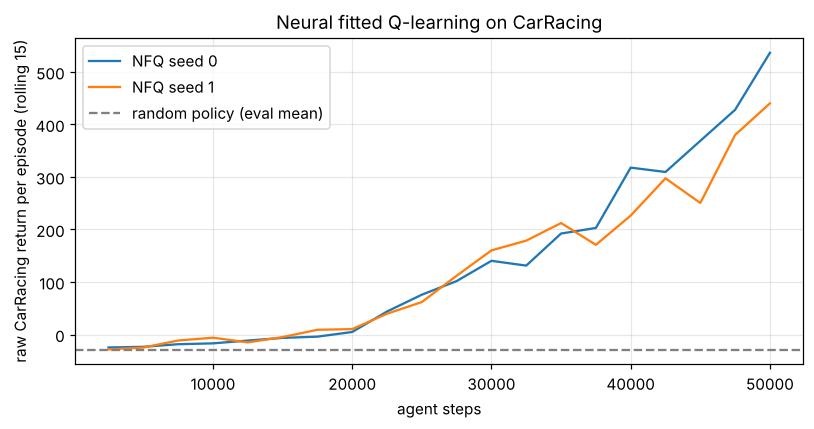

 seed  greedy_mean_return  greedy_std  minutes
    0               -19.9         0.3     30.4
    1               508.0       119.6     28.7
random policy, 10 episodes: mean -28.7 std 9.0


In [8]:
runs = load("nfq"); grid = np.arange(2_500, 50_001, 2_500)
fig, ax = plt.subplots(figsize=(7.5, 4))
for r in runs: ax.plot(grid, smooth(r["hist"], grid), label=f"NFQ seed {r['seed']}")
rnd = [r["random_eval"] for r in runs if r["random_eval"]]
if rnd: ax.axhline(np.mean(rnd[0]), ls="--", c="gray", label="random policy (eval mean)")
ax.set(xlabel="agent steps", ylabel="raw CarRacing return per episode (rolling 15)", title="Neural fitted Q-learning on CarRacing")
ax.legend(); plt.tight_layout(); plt.savefig("../docs/img/m3_nfq_progress.png"); plt.show()
rows = [dict(seed=r["seed"], greedy_mean_return=np.mean(r["eval"]), greedy_std=np.std(r["eval"]), minutes=r["minutes"]) for r in runs]
print(pd.DataFrame(rows).round(1).to_string(index=False))
if rnd: print("random policy, 10 episodes: mean", round(np.mean(rnd[0]), 1), "std", round(np.std(rnd[0]), 1))

## 8. Why is the greedy score so different from the training curve?
The training curve is measured with 5% random actions; the greedy evaluation has none. Two checks per seed: which actions the greedy policy picks in the first 40 steps, and its score on 5 tracks when 5% random actions are added.

In [9]:
import random
rows = []
for r in runs:
    qn = C.QCNN(); qn.load_state_dict(torch.load(f"../models/car_nfq_s{r['seed']}.pt")); qn.eval()
    e = C.CarEnv(); s = e.reset(seed=900_000); acts = []
    for _ in range(40):
        a = C.act_greedy(qn, s); acts.append(a); s, _, d = e.step(a)
        if d: break
    random.seed(0)
    noisy = C.evaluate(qn, episodes=5, policy=lambda s: random.randrange(5) if random.random() < 0.05 else C.act_greedy(qn, s))
    rows.append(dict(seed=r["seed"], greedy_action_counts_first40=str(np.bincount(acts, minlength=5).tolist()),
                     greedy_mean_10_tracks=np.mean(r["eval"]), with_5pct_noise_mean_5_tracks=np.mean(noisy)))
diag = pd.DataFrame(rows).round(1); print("action counts are [noop, right, left, gas, brake]"); print(diag.to_string(index=False))
diag.to_csv("../results/car_nfq_diagnosis.csv", index=False)

action counts are [noop, right, left, gas, brake]
 seed greedy_action_counts_first40  greedy_mean_10_tracks  with_5pct_noise_mean_5_tracks
    0             [0, 0, 40, 0, 0]                  -19.9                          293.7
    1             [0, 4, 7, 29, 0]                  508.0                          481.0


## Takeaways
- A small convolutional Q-network learns to drive CarRacing from raw pixels with no replay and no target network: the rolling training return (with 5% random actions) climbs from about -25 to **~490 at 50,000 agent steps (mean of 2 seeds)**, versus **-28.7** for a random policy evaluated greedily over 10 tracks.
- **The greedy policy is fragile.** Seed 1 scored **508** on 10 unseen tracks, the best of all four CarRacing runs. Seed 0 scored **-19.9** on every track: its greedy policy chose "steer left" on all of the first 40 steps and never accelerated, so the car sat still until the no-progress limit. With 5% random actions the same network averages 294 (one of five tracks still fails at -20). Training curves hid this because they include exploration noise.
- Two seeds are too few to say how often NFQ collapses; they show it can.
- Deviations from the brief: `CarRacing-v3` instead of `-v0`; a CNN feature extractor plus fully connected head instead of a plain MLP; 42x48 grayscale frames, 4-frame stack, action repeat 4; rewards scaled by 0.1; episodes capped at 250 agent steps and ended after 50 steps without progress; 50,000 steps per run.